# Statistical Inference & A/B Testing for Business Decisions

**Session 16 study guide** · Python · pandas · SciPy · statsmodels · signup experiment data

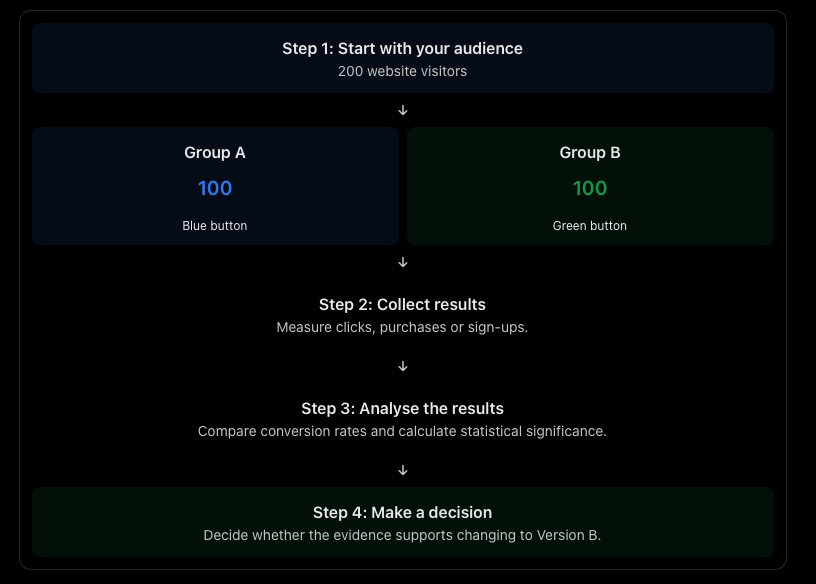

**The business case.** An online bank wants more people to open an account. The product team builds a **simplified signup page (B)** and tests it against the **current page (A)**. For 14 days, each new visitor is randomly shown one of the two pages. The dashboard then shows:

| | Page A (current) | Page B (simplified) |
| --- | --- | --- |
| Signup rate | 12.0% | 13.5% |

The Head of Digital asks one question: **"Should we launch B?"**

"B is higher" is not an answer. Before anyone spends money on a launch, an analyst has to answer six questions, and each part of this guide answers one:

| Part | Question | Tool |
| --- | --- | --- |
| 1 | What exactly was measured? | unit, denominator, percentage points vs relative lift |
| 2 | Could the gap be luck? | sampling variation, standard error |
| 3 | How big could the real effect be? | confidence interval |
| 4 | How surprising is the gap if B does nothing? | hypothesis test, p-value, power |
| 5 | Which test fits which data? | chi-square, t-tests, the tool map |
| 6 | Is it worth acting on? | business threshold, impact in rand, the decision note |

The signup file is synthetic (no real people). Every number and chart below comes from running the code.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import confint_proportions_2indep

BLUE, LIGHT_BLUE, ORANGE, AQUA = "#2a78d6", "#cfe0f6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "font.size": 10,
})

# Decision rules, fixed BEFORE we look at any results
ALPHA = 0.05            # tolerance for a false alarm (Type I error)
BUSINESS_MIN_PP = 2.0   # smallest gain (percentage points) worth the launch cost

The two rules at the bottom are written **before** the data are opened. If we chose them after seeing the result, the data would be choosing the rule used to judge them.

## Part 1 · What exactly was measured?

**Real-life intro.** A restaurant says "90% of diners loved our new dish". Out of 10 diners or 1,000? Out of everyone who ordered it, or only those who filled in a feedback card? A rate means nothing until you know **what one row is** and **what the denominator is**.

In our file one row is **one eligible visitor, assigned once** to A or B. The signup rate for an arm is:

**signup rate = signups in that arm ÷ all visitors assigned to that arm** (people who did not sign up stay in the denominator)

First we audit the file: a test on a broken file cannot be rescued by statistics.

In [3]:
ab = pd.read_csv("S16_AB_Signup_Experiment.csv", parse_dates=["assignment_date"])
ab.head()

,visitor_id,variant,converted,assignment_date
0,V130DBFE333BC5020,A,0,2026-09-04
1,V861EFEE71BA4A577,B,0,2026-09-09
2,V60B569F64AFBC603,B,0,2026-09-10
3,VD3B452404C15A1E7,A,0,2026-09-11
4,VCE4325E62A45F593,B,0,2026-09-05


In [21]:
xmean = np.array([1,2,3,4,5])

In [23]:
(1+2+3+4+5)/5

3.0

In [25]:
3**2

9

In [4]:

print("rows:", len(ab), "| unique visitors:", ab["visitor_id"].nunique())
print("variants:", ab["variant"].value_counts().to_dict())
print("outcomes:", sorted(ab["converted"].unique()), "| missing cells:", ab.isna().sum().sum())
print("dates:", ab["assignment_date"].min().date(), "to", ab["assignment_date"].max().date())

rows: 10000 | unique visitors: 10000
variants: {'A': 5000, 'B': 5000}
outcomes: [np.int64(0), np.int64(1)] | missing cells: 0
dates: 2026-09-01 to 2026-09-14


In [7]:
ab["converted"].value_counts()

converted
0    8725
1    1275
Name: count, dtype: int64

In [12]:
ab.groupby("variant")["converted"].value_counts(normalize=False)

variant  converted
A        0            4400
         1             600
B        0            4325
         1             675
Name: count, dtype: int64

In [14]:
((675-600)/600)*100

12.5

One row per visitor, no duplicates, only A and B, a clean 0/1 outcome, 14 days of assignment. These checks show the **file** is tidy. They cannot show that assignment was truly random, that B actually loaded for every B visitor, or that every signup was logged. Those need the system logs, not the CSV.

         visitors  signups   rate
variant                          
A            5000      600  0.120
B            5000      675  0.135

B - A = +1.5 percentage points | relative lift = +12.5% of A's rate


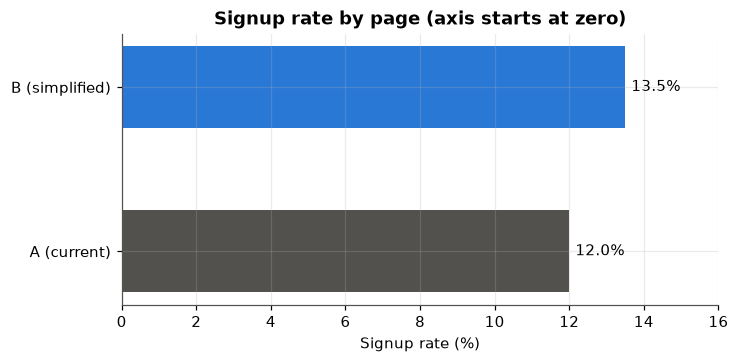

In [15]:
summary = ab.groupby("variant")["converted"].agg(visitors="count", signups="sum", rate="mean")
print(summary)

rate_A, rate_B = summary.loc["A", "rate"], summary.loc["B", "rate"]
diff_pp = (rate_B - rate_A) * 100                    # percentage points
lift_pct = (rate_B - rate_A) / rate_A * 100          # relative to A
print(f"\nB - A = {diff_pp:+.1f} percentage points | relative lift = {lift_pct:+.1f}% of A's rate")

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(["A (current)", "B (simplified)"], summary["rate"] * 100, color=[MUTED, BLUE], height=0.5)
ax.bar_label(bars, labels=[f"{r:.1%}" for r in summary["rate"]], padding=4)
ax.set(xlabel="Signup rate (%)", xlim=(0, 16), title="Signup rate by page (axis starts at zero)")
plt.show()

**Two correct ways to describe the same gap.**

- **+1.5 percentage points (pp):** 13.5% − 12.0%. Use this for the size of the business gap.
- **+12.5% relative lift:** 1.5 ÷ 12.0. Always say "relative to A".

"+1.5 points" is **not** "a 1.5% increase". Marketing decks love the relative number because it sounds bigger; finance needs the points to compute extra customers.

> **Business meaning.** Out of every 1,000 visitors, B produced about 15 more new accounts than A (135 versus 120). That is the number to take to finance. But this is one 14-day sample. Before we celebrate, we have to ask whether a gap this size could appear even if B were no better than A.

## Part 2 · Could the gap be luck? Sampling variation

**Real-life intro.** Flip a fair coin 100 times. You expect 50 heads, but you will often get 46 or 55. The coin did not change; the **sample** did. In the same way, a page with a true 12% signup rate will not produce exactly 600 signups from every 5,000 visitors.

Inference vocabulary, in our case:

| Term | Meaning | In the signup test |
| --- | --- | --- |
| Parameter | the true value we can never see | p_A, p_B: each page's true signup probability |
| Estimate | the number from our one sample | 12.0% and 13.5% |
| Effect | what we want to know | p_B − p_A |

**The experiment:** pretend B does **nothing**. Both pages share one true rate (the pooled 12.75%). Re-run the whole 10,000-visitor test 10,000 times on the computer, and record B − A each time.

SD of simulated gaps: 0.67 pp | formula SE: 0.67 pp
middle 95% of luck-only gaps: [-1.34  1.32] pp


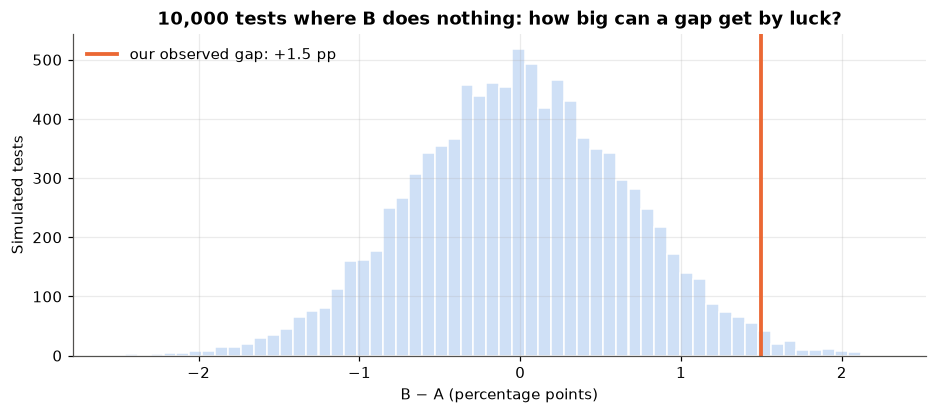

In [16]:
rng = np.random.default_rng(16)
n_A = n_B = 5000

p_pooled = ab["converted"].mean()                    # 12.75%: one rate for both pages

sim_A = rng.binomial(n_A, p_pooled, size=10_000) / n_A
sim_B = rng.binomial(n_B, p_pooled, size=10_000) / n_B
null_diffs_pp = (sim_B - sim_A) * 100                # gaps produced by luck alone

se_formula = np.sqrt(p_pooled * (1 - p_pooled) * (1 / n_A + 1 / n_B)) * 100
print(f"SD of simulated gaps: {null_diffs_pp.std():.2f} pp | formula SE: {se_formula:.2f} pp")
print(f"middle 95% of luck-only gaps: {np.percentile(null_diffs_pp, [2.5, 97.5]).round(2)} pp")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(null_diffs_pp, bins=60, color=LIGHT_BLUE, edgecolor="white")
ax.axvline(diff_pp, color=ORANGE, linewidth=2.5, label=f"our observed gap: {diff_pp:+.1f} pp")
ax.set(xlabel="B − A (percentage points)", ylabel="Simulated tests",
       title="10,000 tests where B does nothing: how big can a gap get by luck?")
ax.legend(frameon=False)
plt.show()

**Reading the chart.** Even when the pages are identical, the gap bounces around zero: the middle 95% of luck-only gaps run from about −1.3 to +1.3 points. Our +1.5 sits **out in the tail**: luck can produce it, but rarely.

The spread of this histogram has a name: the **standard error (SE)**, here about 0.67 pp. The formula SE = √( p(1 − p) × (1/n_A + 1/n_B) ) gives the same number without simulating.

**SD versus SE.** The SD describes how much **individual rows** vary: each visitor is 0 or 1, SD ≈ 0.33. The SE describes how much a **statistic** (a rate or a gap) would vary across repeated tests. SE shrinks with √n: four times the visitors halves the SE. Duplicated rows do not count: they add rows, not information.

> **Business meaning.** A dashboard that shows a gap without its SE invites bad decisions. With 5,000 visitors per page, gaps up to about ±1.3 points happen by chance alone. If the test had only 500 visitors per page, luck alone could produce gaps of about ±4 points, and a +1.5 "win" would be pure noise.

## Part 3 · How big could the real effect be? Confidence intervals

**Real-life intro.** A news poll says "45% support the policy, margin of error ±3 points". The poll gives a best guess (45%) **and** a range (42% to 48%) that reflects sampling noise. A confidence interval does the same for our page effect:

**interval = estimate ± (about 2) × standard error**

Two versions below: the simple formula (to see the logic) and the **Newcombe** interval from statsmodels (more accurate for proportions, the one we predeclared).

simple formula: +1.50 ± 1.96 x 0.667 = [+0.19, +2.81] pp
Newcombe 95% CI: [+0.19, +2.81] pp


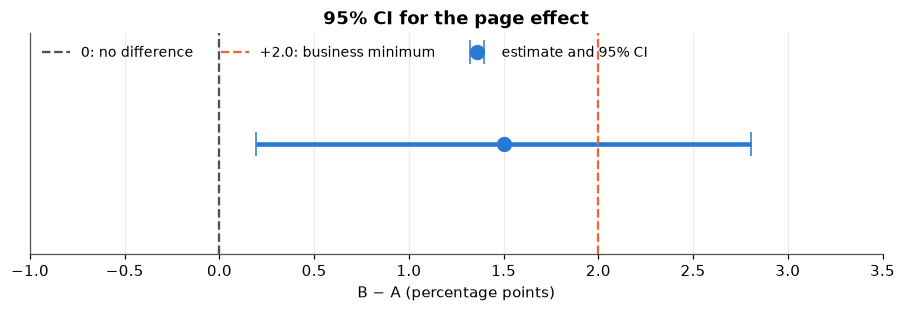

In [19]:
se_diff = np.sqrt(rate_A * (1 - rate_A) / n_A + rate_B * (1 - rate_B) / n_B) * 100
z95 = stats.norm.ppf(0.975)                                   # 1.96
print(f"simple formula: {diff_pp:+.2f} ± {z95:.2f} x {se_diff:.3f} = "
      f"[{diff_pp - z95 * se_diff:+.2f}, {diff_pp + z95 * se_diff:+.2f}] pp")

low, high = confint_proportions_2indep(
    count1=summary.loc["B", "signups"], nobs1=n_B,           # B first, so the gap is B - A
    count2=summary.loc["A", "signups"], nobs2=n_A, method="newcomb")
ci_pp = (low * 100, high * 100)
print(f"Newcombe 95% CI: [{ci_pp[0]:+.2f}, {ci_pp[1]:+.2f}] pp")

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.errorbar(diff_pp, 0, xerr=[[diff_pp - ci_pp[0]], [ci_pp[1] - diff_pp]], fmt="o",
            color=BLUE, capsize=8, linewidth=3, markersize=9, label="estimate and 95% CI")
ax.axvline(0, color=MUTED, linestyle="--", label="0: no difference")
ax.axvline(BUSINESS_MIN_PP, color=ORANGE, linestyle="--", label=f"+{BUSINESS_MIN_PP}: business minimum")
ax.set(yticks=[], xlim=(-1, 3.5), xlabel="B − A (percentage points)", title="95% CI for the page effect")
ax.legend(loc="upper left", frameon=False, ncol=3, fontsize=9)
plt.show()

**Reading the chart.** The plausible effects run from about **+0.2 to +2.8 points**. Read the interval against the two lines:

- **Against 0:** the whole interval is above zero, so the data point to B being better.
- **Against +2.0:** the interval contains values below and above the business minimum. The best estimate (+1.5) is itself below it.

> **Business meaning.** "B is probably better, but we cannot say it is better **by enough**." The true gain could be as small as 0.2 points (about 2 extra accounts per 1,000 visitors, unlikely to repay the build cost) or as large as 2.8 points. The interval turns one number into a range of business outcomes, which is exactly what a risk discussion needs.

**What does "95%" mean?** It is a property of the **method**, not of this one interval. If we repeated the test many times and built an interval each time, about 95% of those intervals would contain the true effect. The simulation below shows it: 20 repeated tests where the true effect really is +1.5 points.

19 of 20 intervals contain the true +1.5 pp


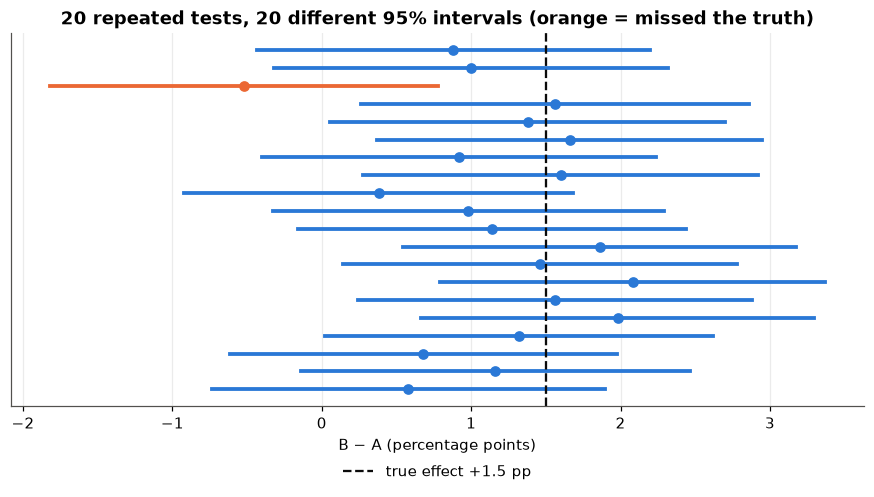

In [20]:
true_A, true_B = 0.120, 0.135                       # pretend we know the truth: +1.5 pp
rng = np.random.default_rng(0)
a = rng.binomial(n_A, true_A, 20) / n_A
b = rng.binomial(n_B, true_B, 20) / n_B
est = (b - a) * 100
half = z95 * np.sqrt(a * (1 - a) / n_A + b * (1 - b) / n_B) * 100
covers = (est - half <= 1.5) & (1.5 <= est + half)
print(f"{covers.sum()} of 20 intervals contain the true +1.5 pp")

fig, ax = plt.subplots(figsize=(10, 4.4))
for i in range(20):
    colour = BLUE if covers[i] else ORANGE
    ax.plot([est[i] - half[i], est[i] + half[i]], [i, i], color=colour, linewidth=2.5)
    ax.plot(est[i], i, "o", color=colour)
ax.axvline(1.5, color=INK, linestyle="--", label="true effect +1.5 pp")
ax.set(yticks=[], xlabel="B − A (percentage points)",
       title="20 repeated tests, 20 different 95% intervals (orange = missed the truth)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

The truth (dashed line) never moves; the intervals do. In real life we see only **one** interval and never know whether it is one of the misses.

> **Watch out.** Avoid saying "there is a 95% probability the true effect is between +0.2 and +2.8". Say "95% of intervals built this way contain the true effect" or "the data are compatible with effects from +0.2 to +2.8 points". And the interval only covers **sampling noise**: it says nothing about broken assignment or missing logs.

## Part 4 · How surprising is the gap if B does nothing? Hypothesis testing

**Real-life intro.** A court starts from "innocent until proven guilty". The prosecutor does not prove innocence false directly; they show the evidence would be **very unlikely if the person were innocent**. A hypothesis test works the same way:

| Court | A/B test |
| --- | --- |
| Presumed innocent | **H₀:** p_B = p_A (the page makes no difference) |
| Accused of the crime | **H₁:** p_B ≠ p_A (two-sided: better **or** worse) |
| "Beyond reasonable doubt" | **α = 0.05**, fixed in advance |
| How unlikely is the evidence if innocent? | **p-value** |
| Guilty / not guilty | reject H₀ / fail to reject H₀ (never "H₀ proven") |

**p-value:** the probability, **if H₀ were true**, of a result at least as extreme as the one we saw. We already have the luck-only simulation from Part 2, so we can count it directly, then confirm with the predeclared test: a **chi-square test** on the 2 × 2 table of counts.

In [7]:
p_simulated = np.mean(np.abs(null_diffs_pp) >= abs(diff_pp))
print(f"share of luck-only tests with a gap of ±{abs(diff_pp):.1f} pp or more: {p_simulated:.4f}\n")

table = pd.crosstab(ab["variant"], ab["converted"]).rename(columns={0: "no signup", 1: "signup"})
chi2, p_value, dof, expected = stats.chi2_contingency(table, correction=False)
print("Observed counts\n", table, "\n")
print("Expected counts if H0 were true\n", pd.DataFrame(expected, index=table.index, columns=table.columns), "\n")
print(f"chi-square({dof}) = {chi2:.3f} | p-value = {p_value:.4f} | alpha = {ALPHA}")
print("Decision:", "reject H0" if p_value < ALPHA else "fail to reject H0")

share of luck-only tests with a gap of ±1.5 pp or more: 0.0254

Observed counts
 converted  no signup  signup
variant                     
A               4400     600
B               4325     675 

Expected counts if H0 were true
 converted  no signup  signup
variant                     
A             4362.5   637.5
B             4362.5   637.5 

chi-square(1) = 5.056 | p-value = 0.0245 | alpha = 0.05
Decision: reject H0


**Reading the output.** If the pages truly performed the same, both arms would expect 637.5 signups (the pooled rate × 5,000). We saw 600 and 675. The chi-square statistic adds up how far each cell is from its expected count: Σ (O − E)² ÷ E = 5.06. The p-value of **0.0245** matches the simulation (about 0.025): a gap this large would happen in only about 2.5% of tests if B did nothing. That is below α = 0.05, so we **reject H₀**.

> **Business meaning.** The test says the difference is **unlikely to be just luck**. It does **not** say how big the gain is (that is the interval's job), that there is a 97.5% chance B works, or that B is worth launching. A tiny, commercially useless gain measured on millions of visitors would also give a small p-value.

**Two ways to be wrong**

| | We reject H₀ | We fail to reject H₀ |
| --- | --- | --- |
| B really does nothing | **Type I error** (false alarm): launch a useless page. Rate = α | correct |
| B really helps | correct (detection) | **Type II error** (missed opportunity): shelve a good page |

**Power** = the chance of detecting an effect that really exists = 1 − P(Type II). It depends on the true effect size, the noise and the number of visitors. Planning teams use it **before** the test to decide how many visitors they need.

+1.5 pp: power with 5,000 per arm = 61% | visitors per arm for 80% power ≈ 8,000
+2.0 pp: power with 5,000 per arm = 84% | visitors per arm for 80% power ≈ 4,500


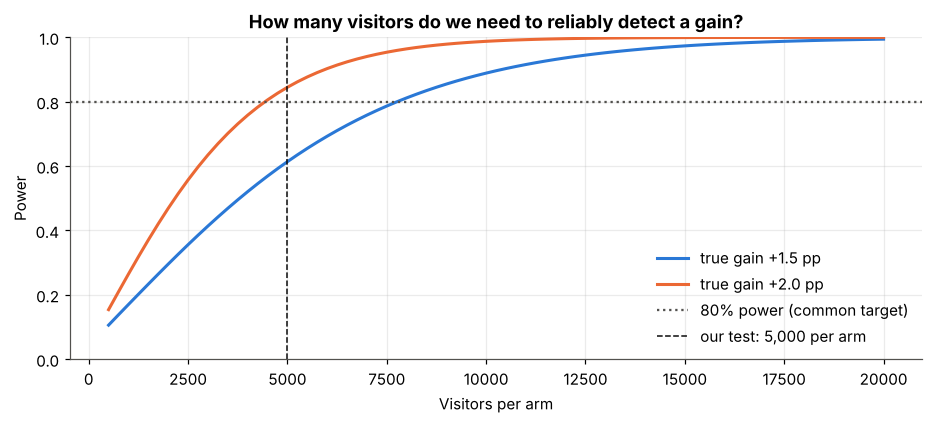

In [8]:
def power_two_rates(p_base, effect_pp, n_per_arm, alpha=ALPHA):
    """Approximate power of a two-sided test of two rates (normal approximation)."""
    p_new = p_base + effect_pp / 100
    se = np.sqrt(p_base * (1 - p_base) / n_per_arm + p_new * (1 - p_new) / n_per_arm)
    return stats.norm.cdf(abs(effect_pp / 100) / se - stats.norm.ppf(1 - alpha / 2))

n_grid = np.arange(500, 20_001, 250)
fig, ax = plt.subplots(figsize=(10, 3.8))
for effect, colour in [(1.5, BLUE), (2.0, ORANGE)]:
    power = power_two_rates(rate_A, effect, n_grid)
    ax.plot(n_grid, power, color=colour, linewidth=2, label=f"true gain +{effect} pp")
    need = n_grid[np.argmax(power >= 0.8)]
    print(f"+{effect} pp: power with 5,000 per arm = {power_two_rates(rate_A, effect, 5000):.0%} | "
          f"visitors per arm for 80% power ≈ {need:,}")
ax.axhline(0.8, color=MUTED, linestyle=":", label="80% power (common target)")
ax.axvline(5000, color=INK, linestyle="--", linewidth=1, label="our test: 5,000 per arm")
ax.set(xlabel="Visitors per arm", ylabel="Power", ylim=(0, 1),
       title="How many visitors do we need to reliably detect a gain?")
ax.legend(frameon=False, loc="lower right")
plt.show()

**Reading the chart.** With 5,000 visitors per page, a real +2.0-point gain would be detected about 8 times in 10 (84%), but a real +1.5-point gain only about 6 times in 10 (61%). Detecting +1.5 reliably would need about 8,000 visitors per page. Smaller effects need many more visitors.

> **Business meaning.** Power is a **planning** tool. Before the next test, the team can say: "we care about +2 points, we need about 4,500 visitors per page, and our traffic gives us that in about two weeks." A test that is too small wastes two weeks and will probably "fail to reject" even if the page is good, and then someone will wrongly conclude "the new page doesn't work".

## Part 5 · Which test fits which data?

Pick the test from **the type of outcome** and **the number of groups**, never from which one gives the smallest p-value.

| Business question | Outcome | Groups | Test (Python) |
| --- | --- | --- | --- |
| Did page B change the signup rate? | yes/no per person (counts) | 2 or more | chi-square: `stats.chi2_contingency` |
| Is our mean call time different from the 18-min target? | a number | 1 vs a target | one-sample t: `stats.ttest_1samp` |
| Is the new workflow faster than the old one? | a number | 2 independent | Welch t: `stats.ttest_ind(..., equal_var=False)` |
| Do three branches have the same mean wait time? | a number | 3 or more | one-way ANOVA: `stats.f_oneway` |
| Is a mean different from a target when the population SD is truly known? | a number | 1 | Z-test (rare in business) |

The signup outcome is yes/no, so it gets the chi-square test. For **numbers** (time, spend, balance) we use t-tests.

**Second business case: the bank's call centre.** The SLA target for handling a support call is **18 minutes**. The operations team pilots a **new workflow** on a random set of calls. Below we simulate 60 randomly chosen calls under each workflow (call times are right-skewed: most are quick, a few drag on).

          count   mean  median   std
workflow                            
current      60  19.71   18.55  5.09
new          60  16.43   16.50  4.28


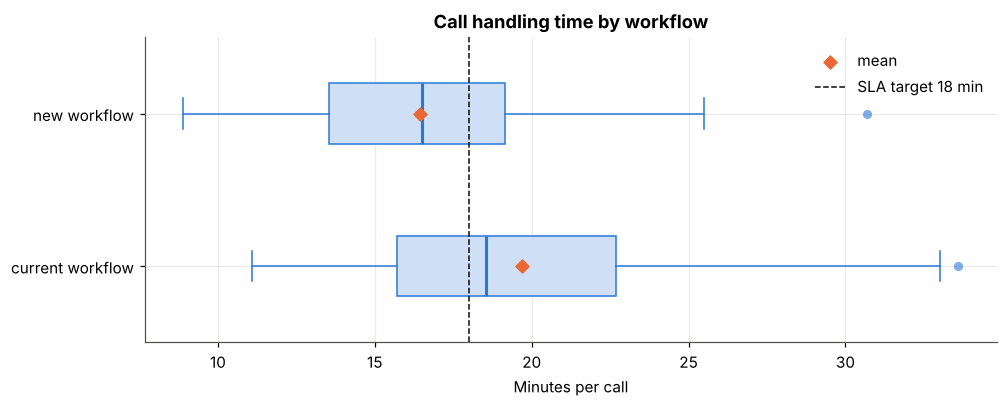

In [9]:
rng = np.random.default_rng(2)
calls = pd.DataFrame({
    "workflow": ["current"] * 60 + ["new"] * 60,
    "minutes": np.concatenate([rng.gamma(16, 1.22, 60), rng.gamma(16, 1.03, 60)]).round(1),
})
current = calls.loc[calls["workflow"] == "current", "minutes"]
new = calls.loc[calls["workflow"] == "new", "minutes"]
print(calls.groupby("workflow")["minutes"].agg(["count", "mean", "median", "std"]).round(2))

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.boxplot([current, new], positions=[0, 1], widths=0.4, orientation="horizontal", patch_artist=True,
           boxprops=dict(facecolor=LIGHT_BLUE, edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
           flierprops=dict(marker="o", markerfacecolor=BLUE, markeredgecolor="none", alpha=0.6))
ax.scatter([current.mean(), new.mean()], [0, 1], marker="D", color=ORANGE, zorder=5, label="mean")
ax.axvline(18, color=INK, linestyle="--", linewidth=1, label="SLA target 18 min")
ax.set_yticks([0, 1], ["current workflow", "new workflow"])
ax.set(xlabel="Minutes per call", title="Call handling time by workflow")
ax.legend(frameon=False, loc="upper right")
plt.show()

In [10]:
# 1) One-sample t-test: does the CURRENT workflow meet the 18-minute target?
t1 = stats.ttest_1samp(current, popmean=18)
ci1 = t1.confidence_interval()
print(f"current mean {current.mean():.2f} min | t = {t1.statistic:.2f}, p = {t1.pvalue:.4f} | "
      f"95% CI [{ci1.low:.2f}, {ci1.high:.2f}]")

# 2) Welch two-sample t-test: is the NEW workflow different from the current one?
t2 = stats.ttest_ind(new, current, equal_var=False)          # new first -> difference = new - current
ci2 = t2.confidence_interval()
print(f"new - current = {new.mean() - current.mean():+.2f} min | t = {t2.statistic:.2f}, "
      f"p = {t2.pvalue:.4f} | 95% CI [{ci2.low:+.2f}, {ci2.high:+.2f}]")

current mean 19.71 min | t = 2.60, p = 0.0119 | 95% CI [18.39, 21.02]
new - current = -3.28 min | t = -3.82, p = 0.0002 | 95% CI [-4.98, -1.58]


**Reading the output.**

- **One-sample t:** the current workflow averages about 19.7 minutes. Its 95% interval (18.4 to 21.0) sits entirely above 18, and p ≈ 0.012, so the data suggest the current process is **missing the SLA**, by roughly 0.4 to 3 minutes on average.
- **Welch t:** the new workflow is about 3.3 minutes faster on average (95% interval −5.0 to −1.6 minutes, p ≈ 0.0002). Welch's version does not assume both groups have the same spread, which makes it the safe default. Putting `new` first makes the difference new − current, so negative means faster.

We use t (not Z) because the SD is estimated from the sample, and "n ≥ 30 means Z" is not a rule.

> **Business meaning.** The current process breaches the 18-minute SLA, and the new workflow gives a clear, detectable saving of about 3 minutes per call and brings the average under target. Whether to roll it out is again a business question: 3 minutes × calls per month × cost per agent-minute, against training cost and customer satisfaction (a faster call that does not solve the problem creates repeat calls, so track a guardrail such as "first-call resolution").

> **Watch out.** A t-test compares **means**, so check the box plot for big outliers first. And the calls must be **independent**: 60 calls from 3 agents are not 60 independent pieces of evidence.

## Part 6 · Is it worth acting on? From statistics to a decision

Back to the signup page. Three different claims, three different kinds of evidence:

| Claim | Evidence | Our answer |
| --- | --- | --- |
| The difference is not just luck | p-value, interval vs 0 | **Yes**: p = 0.0245, interval above 0 |
| The gain is big enough to launch | interval vs the +2.0 business minimum | **Not established**: estimate +1.5, interval spans +2.0 |
| The page **caused** the gain | design: random assignment, exposure, logging | **Only if the design held**: the CSV cannot prove it |

**Statistical vs practical significance.** The four intervals below (illustrative, except the last) show why "significant" is not the same as "worth it".

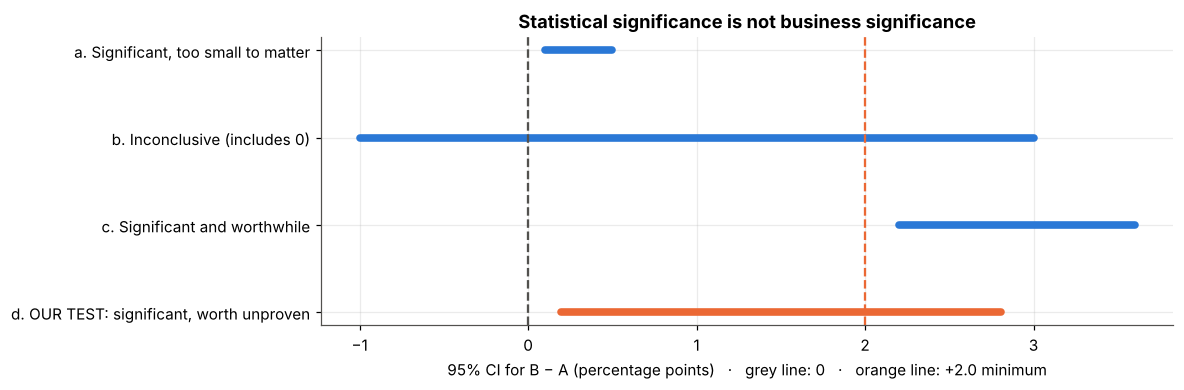

In [11]:
cases = {
    "a. Significant, too small to matter": (0.1, 0.5),
    "b. Inconclusive (includes 0)": (-1.0, 3.0),
    "c. Significant and worthwhile": (2.2, 3.6),
    "d. OUR TEST: significant, worth unproven": ci_pp,
}
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (label, (lo, hi)) in enumerate(cases.items()):
    colour = ORANGE if label.startswith("d") else BLUE
    ax.plot([lo, hi], [i, i], color=colour, linewidth=5, solid_capstyle="round")
ax.axvline(0, color=MUTED, linestyle="--")
ax.axvline(BUSINESS_MIN_PP, color=ORANGE, linestyle="--")
ax.set_yticks(range(len(cases)), cases.keys())
ax.invert_yaxis()
ax.set(xlabel="95% CI for B − A (percentage points)   ·   grey line: 0   ·   orange line: +2.0 minimum",
       title="Statistical significance is not business significance")
plt.show()

**Turn points into rand.** The interval becomes a business range once we add traffic and value. The figures below are **assumptions for illustration**: 100,000 eligible visitors a month, R150 first-year profit per new account, and R300,000 a month as the cost of the change (build, compliance review and support, spread over the first year).

In [12]:
visitors_per_month = 100_000      # assumption
value_per_signup = 150            # rand of first-year profit, assumption
monthly_cost = 300_000            # rand, assumption

for label, gain_pp in [("low end of CI", ci_pp[0]), ("estimate", diff_pp),
                       ("business minimum", BUSINESS_MIN_PP), ("high end of CI", ci_pp[1])]:
    extra = visitors_per_month * gain_pp / 100
    net = extra * value_per_signup - monthly_cost
    print(f"{label:<17} {gain_pp:+.2f} pp -> {extra:>5,.0f} extra signups -> net R{net:>10,.0f} per month")

low end of CI     +0.19 pp ->   192 extra signups -> net R  -271,146 per month
estimate          +1.50 pp -> 1,500 extra signups -> net R   -75,000 per month
business minimum  +2.00 pp -> 2,000 extra signups -> net R         0 per month
high end of CI    +2.81 pp -> 2,808 extra signups -> net R   121,206 per month


> **Business meaning.** Under these assumptions B only pays for itself from +2.0 points upwards, which is exactly why management set +2.0 as the minimum. At the low end of the interval B would lose about R270,000 a month, and even at the best estimate (+1.5) it would lose about R75,000. Only the top part of the interval is profitable. The p-value alone would have said "launch".

**Before trusting any A/B result, check the design.**

In [13]:
# Sample ratio mismatch (SRM): does the A/B split match the planned 50:50?
srm = stats.binomtest(int((ab["variant"] == "B").sum()), n=len(ab), p=0.5)
print(f"B share = {(ab['variant'] == 'B').mean():.1%} | SRM p-value = {srm.pvalue:.3f}")

B share = 50.0% | SRM p-value = 1.000


The split is exactly 5,000 / 5,000, so there is no sign of a broken assignment. (A real test would rarely be this perfect; a split like 5,200 / 4,800 would give p ≈ 0.0001 and should stop the analysis until the routing is checked.)

| Pitfall | What goes wrong | Prevention |
| --- | --- | --- |
| Wrong unit | page views or sessions counted instead of people | one row per visitor, assigned once |
| Sample ratio mismatch | broken routing or logging | compare arm counts with the plan |
| Peeking | stopping the first day p < 0.05 inflates false alarms | fix the test length in advance |
| Metric shopping | testing 10 metrics and reporting the one that "won" | one primary metric, declared first |
| Moving the goalposts | changing +2.0 after seeing +1.5 | write the rules before the data |
| Ignoring guardrails | more signups but more crashes, fraud or support calls | track guardrail metrics |

### The decision note

> **Decision note.** Among 10,000 eligible visitors randomly assigned in this synthetic 14-day test, the signup rate was 12.0% on page A and 13.5% on page B: +1.5 percentage points, or +12.5% relative to A. The predeclared chi-square test gave χ²(1) = 5.06, p = 0.0245, so the gap is unlikely to be chance alone, and the 95% interval for B − A was +0.2 to +2.8 points. The estimate is below the +2.0-point minimum and the interval spans it, so a worthwhile gain is not established; at the low end B would not repay its cost. The file cannot confirm that assignment was truly random, that B loaded for every visitor, or that guardrails such as page errors held. I recommend **not** launching B to everyone yet: verify the logs and guardrails, then run a longer test (about 4,500+ visitors per arm for 80% power at +2.0 points) or a staged rollout.

### Practical tasks · try it yourself

1. Write the design record **before** running anything: unit, metric and denominator, H₀ and H₁, α, the business minimum.
2. Recompute the rates, B − A in points and the relative lift. Which would you put in a board pack?
3. Rerun `p4_test.py` with `correction=True`. Why must the choice be made before seeing the result?
4. Change `value_per_signup` to R250 in `p6_impact.py`. Where is the new break-even point, and does the decision change?
5. Write your own 5–7 sentence decision note.

In [14]:
# Your work here

### Summary: say it correctly

| Avoid | Say instead |
| --- | --- |
| "B increased signups by 1.5%" | "+1.5 percentage points, +12.5% relative to A" |
| "p = 0.02 means a 98% chance B works" | "if B made no difference, a gap this large would occur about 2% of the time" |
| "95% chance the effect is in the interval" | "95% of intervals built this way contain the true effect" |
| "p > 0.05, so the pages are the same" | "we failed to reject H₀; the test may be too small to tell" |
| "significant, so launch" | "significant; now check size, cost, guardrails and design" |

**Next session (17):** Math Foundations for Machine Learning: vectors, matrices and gradient descent. *Signup data: S16_AB_Signup_Experiment.csv, fully synthetic. Call-centre data are simulated in the notebook (seed 2).*